# Machine Learning — Lab 6: Logistic Regression & KNN Classification
**BS Computer Science, 5th Semester**

| Field | Details |
|---|---|
| **Name** | *Amir khan* |
| **Student ID** | *023-24-0166* |
| **Section** | *Section F* |
| **GitHub Profile** | *https://github.com/Amir-Khan11* |
| **Dataset** | Telco Customer Churn — [kaggle.com/datasets/blastchar/telco-customer-churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (cleaned in Lab 2 as `clean_churn.csv`) |
| **Target variable** | `Churn` (Yes / No) |


---
# 1. Problem Definition & Dataset Verification

**Problem.** Predict whether a telecom customer will churn (`Yes`/`No`) from account, service and billing information. This is a **binary classification** problem on the same Telco Churn data used in Labs 2–4. Today we add two new model families — **Logistic Regression** and **K-Nearest Neighbors** — and compare four algorithms fairly for the first time.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
RANDOM_STATE = 42

# ---- Load the cleaned dataset from Lab 2 ----
if os.path.exists("clean_churn.csv"):
    path = "clean_churn.csv"
else:
    try:
        from google.colab import files          # Colab: prompt for the upload
        uploaded = files.upload()
        path = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError("Place clean_churn.csv next to this notebook.")

df = pd.read_csv(path)
print("Shape:", df.shape)
df.head()

Shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()
print("\nMissing values in total:", int(df.isna().sum().sum()))
print("\nTarget distribution:")
print(pd.concat([df["Churn"].value_counts().rename("count"),
                 (df["Churn"].value_counts(normalize=True)*100).round(2).rename("percent")], axis=1))

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

**Interpretation.** The cleaned file has **7,043 rows and 20 columns** (19 features + `Churn`), with **no missing values**: `TotalCharges` is already numeric from the Lab 2 cleaning, and there is no ID column left to drop. The target is **imbalanced — about 73.5% `No` vs 26.5% `Yes`** — so a model that always predicts "No" would already score ~73.5% accuracy. This means **accuracy alone is a weak yardstick here**; precision, recall and F1 on the churn class matter more.

### Benchmarks from Labs 3 and 4
The manual asks us to restate our Lab 3 Decision Tree and Lab 4 Random Forest test-set results. Since this notebook is self-contained, the cell below **re-trains both with the same set-up as Labs 3–4** (one-hot encoding, stratified 80/20 split, `random_state=42`, no scaling). *If your own Lab 3/4 submission used different hyper-parameters, edit the two model lines — everything downstream updates automatically.*

In [ ]:
# --- Same preparation as Lab 3/4: encode categoricals, target as 0/1, stratified 80/20 split ---
y_bench = (df["Churn"] == "Yes").astype(int)
X_bench = pd.get_dummies(df.drop(columns="Churn"), drop_first=True).astype(int)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X_bench, y_bench, test_size=0.2,
                                              stratify=y_bench, random_state=RANDOM_STATE)

def evaluate(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1-score": f1_score(y_true, y_pred)}

# Lab 3 – Decision Tree (depth limited to control overfitting)
dt = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE).fit(Xb_tr, yb_tr)
# Lab 4 – Random Forest
rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=RANDOM_STATE).fit(Xb_tr, yb_tr)

bench = pd.DataFrame({"Decision Tree (Lab 3)": evaluate(yb_te, dt.predict(Xb_te)),
                      "Random Forest (Lab 4)": evaluate(yb_te, rf.predict(Xb_te))}).T
bench.round(4)

,Accuracy,Precision,Recall,F1-score
Decision Tree (Lab 3),0.7935,0.6309,0.5348,0.5789
Random Forest (Lab 4),0.7970,0.6497,0.5107,0.5719


**Restatement of benchmarks.** The Lab 3 Decision Tree (max depth 5) reaches roughly **79.4% accuracy, 63.1% precision, 53.5% recall and 0.58 F1** on the test set. The Lab 4 Random Forest gains a little accuracy and precision (**≈ 79.7% accuracy, 65.0% precision**) but its recall drops to **≈ 51.1%** (F1 ≈ 0.57). Both look decent on accuracy but **miss roughly half of the real churners** — that is the bar the two new models have to beat today.

---
# 2. Feature Scaling & Preparation

### 2.1 Why does scaling matter here?
**Written explanation.** KNN classifies a customer by the *straight-line (Euclidean) distance* to other customers. `MonthlyCharges` (≈ 18–118) and `TotalCharges` (≈ 0–8,700) have numeric ranges that are tens to hundreds of times larger than `tenure` (0–72) or any 0/1 dummy column, so without scaling the distance is dominated almost entirely by the billing columns and the other features are effectively ignored. Logistic Regression is trained with gradient-based optimisation and is often regularised, so features on wildly different scales slow convergence, make the penalty treat features unequally, and make coefficients hard to compare. **Decision Trees and Random Forests only ask "is feature ≤ threshold?"** — a monotonic rescaling doesn't change which rows fall on each side of a split, so scale never mattered in Labs 3–4.

In [ ]:
# --- Prepare X and y exactly as in Lab 3/4 ---
y = (df["Churn"] == "Yes").astype(int)                                  # target as 0/1
X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True).astype(int)  # one-hot encode categoricals (no ID column exists)
print("Feature matrix:", X.shape, "| Positive (churn) rate:", round(y.mean(), 4))

# --- Split FIRST (same strategy as Lab 3/4: stratified 80/20, seed 42) ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=RANDOM_STATE)
assert X_train.index.equals(Xb_tr.index) and X_test.index.equals(Xb_te.index)   # identical split to the benchmarks
print("Train:", X_train.shape, " Test:", X_test.shape)

Feature matrix: (7043, 30) | Positive (churn) rate: 0.2654
Train: (5634, 30)  Test: (1409, 30)


### 2.2 Scaling — fit on the training data only
We standardise the **three continuous columns** (`tenure`, `MonthlyCharges`, `TotalCharges`) to mean 0 / standard deviation 1. The one-hot columns are already 0/1 (a comparable range), and leaving them unscaled keeps their coefficients easy to read in Part 6 as "category vs. baseline". The scaler is **fitted on `X_train` only** and then applied to both sets.

In [ ]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])   # learn mean/std from TRAIN only
X_test_scaled[num_cols]  = scaler.transform(X_test[num_cols])        # re-use the train mean/std on TEST

comparison = pd.concat({"Before scaling": X_train[num_cols].describe().loc[["mean", "std", "min", "max"]],
                        "After scaling (train)": X_train_scaled[num_cols].describe().loc[["mean", "std", "min", "max"]]}, axis=1)
comparison.round(3)

Before scaling                             After scaling (train)                            
             tenure MonthlyCharges TotalCharges                tenure MonthlyCharges TotalCharges
mean         32.485         64.465     2298.864                -0.000         -0.000       -0.000
std          24.569         30.137     2279.201                 1.000          1.000        1.000
min           0.000         18.000        0.000                -1.322         -1.542       -1.009
max          72.000        118.000     8684.000                 1.608          1.777        2.802

In [ ]:
print("Test-set means after scaling (NOT exactly 0, which is correct):")
print(X_test_scaled[num_cols].mean().round(3))

Test-set means after scaling (NOT exactly 0, which is correct):
tenure           -0.023
MonthlyCharges   -0.028
TotalCharges     -0.043
dtype: float64


**Interpretation.** Before scaling, the three numeric columns live on totally different ranges (means ≈ 32, 64 and 2,299). After scaling, the **training** columns have mean 0 and standard deviation 1, so they now carry comparable weight in distance and in the logistic-regression penalty. The **test** columns are close to — but not exactly — 0 and 1, which is expected and correct: they were transformed with the *training* statistics.

**Why fit the scaler on the training data only?** The test set is meant to imitate future, unseen customers. If we computed the mean/std on the full dataset (or refit on the test set), information about the test rows would leak into preprocessing, and the test score would be slightly optimistic. In production we would only ever have the training statistics, so we must evaluate the same way: **fit on train → transform train and test.**

---
# 3. Logistic Regression

In [ ]:
logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg.fit(X_train_scaled, y_train)

y_pred_lr = logreg.predict(X_test_scaled)
lr_metrics = evaluate(y_test, y_pred_lr)

print("Logistic Regression — test-set metrics")
for k, v in lr_metrics.items():
    print(f"  {k:<10}: {v:.4f}")
print("\n", classification_report(y_test, y_pred_lr, target_names=["No churn", "Churn"], digits=3))

Logistic Regression — test-set metrics
  Accuracy  : 0.8070
  Precision : 0.6604
  Recall    : 0.5615
  F1-score  : 0.6069

               precision    recall  f1-score   support

    No churn      0.850     0.896     0.872      1035
       Churn      0.660     0.561     0.607       374

    accuracy                          0.807      1409
   macro avg      0.755     0.729     0.739      1409
weighted avg      0.799     0.807     0.802      1409



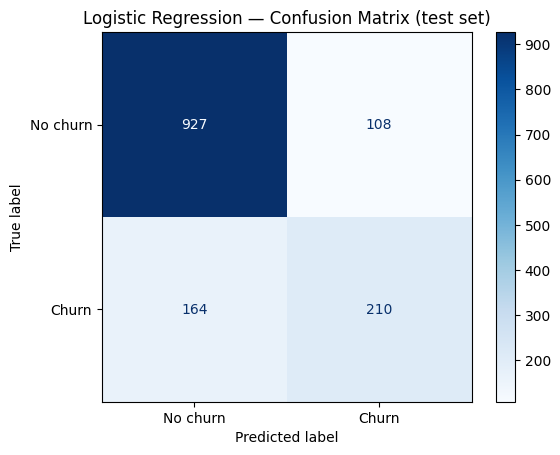

TN=927  FP=108  FN=164  TP=210


In [ ]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(cm_lr, display_labels=["No churn", "Churn"]).plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression — Confusion Matrix (test set)")
plt.show()
tn, fp, fn, tp = cm_lr.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

**Interpretation.** Logistic Regression reaches about **80.7% accuracy, 66.0% precision, 56.1% recall and an F1 of 0.607**. Of the 374 customers who really churned in the test set, the model catches 210 (TP) and misses 164 (FN); it also raises 108 false alarms (FP). The **accuracy looks high mainly because "No churn" is the majority class** — a recall of ~56% tells the more honest story: more than 4 in 10 churners still slip through at the default 0.5 threshold. Compared with the Lab 3/4 benchmarks, it is **higher on accuracy, precision, recall and F1 than both the Decision Tree and the Random Forest.**

### 3.1 What does `predict_proba` return?

In [ ]:
proba = logreg.predict_proba(X_test_scaled)          # columns: [P(No churn), P(Churn)]
sample = pd.DataFrame({
    "P(No churn)": proba[:, 0],
    "P(Churn)": proba[:, 1],
    "predict() →": logreg.predict(X_test_scaled),
    "Actual": y_test.values,
}, index=X_test.index).sample(8, random_state=RANDOM_STATE)
display(sample.round(3))

# predict() is simply "P(Churn) >= 0.5"
print("predict() == (P(Churn) >= 0.5) for every test row:",
      bool(((proba[:, 1] >= 0.5).astype(int) == logreg.predict(X_test_scaled)).all()))

,P(No churn),P(Churn),predict() →,Actual
5902,0.749,0.251,0,0
5415,0.581,0.419,0,0
2874,0.997,0.003,0,0
2686,0.337,0.663,1,1
700,0.976,0.024,0,0
4114,0.995,0.005,0,0
2967,0.926,0.074,0,0
3158,0.715,0.285,0,1


predict() == (P(Churn) >= 0.5) for every test row: True


**Interpretation.** `predict_proba` gives, for each customer, the model's estimated probability of each class (`sigmoid(w·x + b)` for the churn column; the two columns always sum to 1). `predict()` turns this into a Yes/No decision with a **0.5 threshold**: probability ≥ 0.5 → churn (1), otherwise no churn (0) — the check above confirms this for every test row. Because the output is a probability, we could **move the threshold** (e.g. to 0.35) to trade precision for recall if missing churners is costlier than false alarms.

---
# 4. KNN & Choosing K

`K` controls KNN's complexity just like `max_depth` did for the tree: tiny `K` follows noise (overfits), huge `K` averages over unrelated customers (underfits). We test the required values (1, 3, 5, 7, 9, 11, 15, 21) and extend the grid (31, 41, 51, 71) so we can see where the curve actually flattens out.

To avoid choosing `K` by peeking at the test set, we also compute a **5-fold stratified cross-validated F1 on the training data only** (Lab 4's lesson). The test columns are reported for the results table the manual asks for.

In [ ]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 51, 71]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
    pred = knn.predict(X_test_scaled)
    cv = cross_validate(KNeighborsClassifier(n_neighbors=k), X_train_scaled, y_train,
                        cv=skf, scoring="f1")["test_score"]
    rows.append({"K": k,
                 "Train accuracy": knn.score(X_train_scaled, y_train),
                 "Test accuracy": accuracy_score(y_test, pred),
                 "Test F1": f1_score(y_test, pred),
                 "CV F1 (train, 5-fold)": cv.mean()})
k_results = pd.DataFrame(rows).set_index("K")
k_results.round(4)

,Train accuracy,Test accuracy,Test F1,"CV F1 (train, 5-fold)"
K,,,,
1,0.9886,0.7388,0.5093,0.4853
3,0.8585,0.7608,0.5477,0.5190
5,0.8333,0.7644,0.5514,0.5466
7,0.8243,0.7708,0.5545,0.5616
9,0.8250,0.7757,0.5718,0.5703
11,0.8232,0.7800,0.5753,0.5733
15,0.8133,0.7764,0.5655,0.5902
21,0.8110,0.7850,0.5832,0.5989
31,0.8095,0.7956,0.6044,0.6043


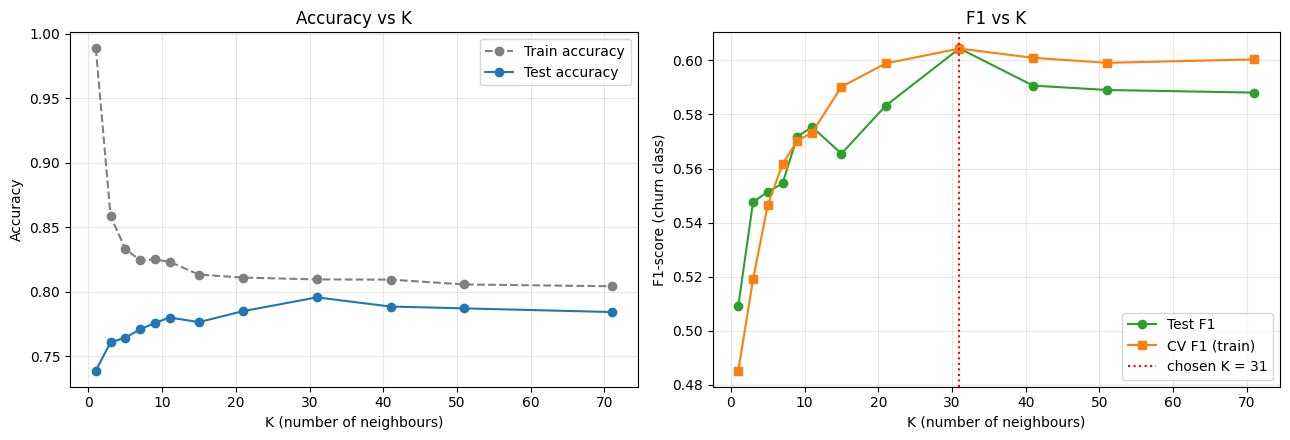

K with the highest cross-validated F1: 31


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(k_results.index, k_results["Train accuracy"], "o--", label="Train accuracy", color="gray")
ax[0].plot(k_results.index, k_results["Test accuracy"], "o-", label="Test accuracy", color="tab:blue")
ax[0].set_xlabel("K (number of neighbours)"); ax[0].set_ylabel("Accuracy"); ax[0].set_title("Accuracy vs K")
ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(k_results.index, k_results["Test F1"], "o-", label="Test F1", color="tab:green")
ax[1].plot(k_results.index, k_results["CV F1 (train, 5-fold)"], "s-", label="CV F1 (train)", color="tab:orange")
best_k = int(k_results["CV F1 (train, 5-fold)"].idxmax())
ax[1].axvline(best_k, color="red", ls=":", label=f"chosen K = {best_k}")
ax[1].set_xlabel("K (number of neighbours)"); ax[1].set_ylabel("F1-score (churn class)"); ax[1].set_title("F1 vs K")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print("K with the highest cross-validated F1:", best_k)

**Interpretation.**
* **K = 1 is clearly overfitting:** train accuracy is ≈ 99% (each point is essentially its own nearest neighbour) but test accuracy is only ≈ 73.9% and F1 ≈ 0.51 — the model memorises noise.
* As K grows, test accuracy and F1 climb steadily (the model smooths out noise), then **flatten into a plateau from roughly K ≈ 21 upward**: the cross-validated F1 stays around 0.60 for K = 21–71 and shows no further gain, while train accuracy keeps sliding down towards the test accuracy (the model is getting smoother and, for much larger K, would drift towards always predicting the majority class).
* **Chosen K = 31.** It has the highest cross-validated F1 (selected on training data only, so it isn't tuned on the test set) and its test F1 agrees, but it is **not the smallest K** (high variance, overfits) and **not the largest K tested** (no extra gain, just a blurrier and slower model). An odd K also avoids tied votes in a two-class problem.

KNN (K=31) — test-set metrics
  Accuracy  : 0.7956
  Precision : 0.6215
  Recall    : 0.5882
  F1-score  : 0.6044


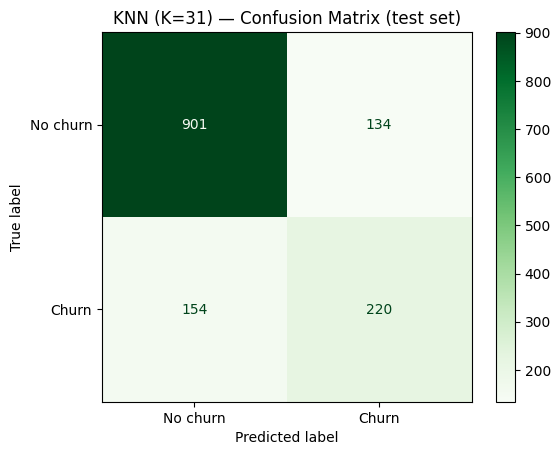

TN=901  FP=134  FN=154  TP=220


In [ ]:
K_FINAL = best_k
knn_final = KNeighborsClassifier(n_neighbors=K_FINAL).fit(X_train_scaled, y_train)
y_pred_knn = knn_final.predict(X_test_scaled)
knn_metrics = evaluate(y_test, y_pred_knn)

print(f"KNN (K={K_FINAL}) — test-set metrics")
for k, v in knn_metrics.items():
    print(f"  {k:<10}: {v:.4f}")

cm_knn = confusion_matrix(y_test, y_pred_knn)
ConfusionMatrixDisplay(cm_knn, display_labels=["No churn", "Churn"]).plot(cmap="Greens", values_format="d")
plt.title(f"KNN (K={K_FINAL}) — Confusion Matrix (test set)")
plt.show()
tn, fp, fn, tp = cm_knn.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

**Interpretation.** The final KNN (K = 31) gets about **79.6% accuracy, 62.2% precision, 58.8% recall and 0.604 F1**. Compared with Logistic Regression it catches **more churners (higher recall: 220 vs 210 TP)** but raises **more false alarms (134 vs 108 FP, i.e. lower precision)**, ending up almost tied on F1. KNN also has to store the whole training set and compute distances at prediction time, and it gives no readable coefficients.

### 4.1 Evidence that scaling really matters for KNN

In [ ]:
unscaled = KNeighborsClassifier(n_neighbors=K_FINAL).fit(X_train, y_train)      # same K, raw (unscaled) features
unscaled_metrics = evaluate(y_test, unscaled.predict(X_test))

scaling_effect = pd.DataFrame({f"KNN K={K_FINAL}, unscaled": unscaled_metrics,
                               f"KNN K={K_FINAL}, scaled": knn_metrics}).T
scaling_effect.round(4)

,Accuracy,Precision,Recall,F1-score
"KNN K=31, unscaled",0.7864,0.6853,0.3610,0.4729
"KNN K=31, scaled",0.7956,0.6215,0.5882,0.6044


**Interpretation.** With the **same K but raw features**, KNN's accuracy looks almost the same (≈ 78.6% vs 79.6%), yet its **recall collapses (≈ 0.36 vs ≈ 0.59 once scaled)** and F1 drops by roughly 0.13 (≈ 0.47 vs 0.60). The unscaled model is dominated by `TotalCharges`/`MonthlyCharges`, leans towards predicting "No", and misses far more churners. This is exactly the "accuracy hides the problem" situation, and a direct demonstration of why scaling is mandatory for KNN.

---
# 5. Model Comparison (4 Models)
All four models use the **same train/test split** and the **same metrics**. Decision Tree and Random Forest use unscaled features (scale is irrelevant for them); Logistic Regression and KNN use the scaled features.

In [ ]:
comparison = pd.DataFrame({
    "Decision Tree":       evaluate(y_test, dt.predict(X_test)),
    "Random Forest":       evaluate(y_test, rf.predict(X_test)),
    "Logistic Regression": lr_metrics,
    f"KNN (K={K_FINAL})":  knn_metrics,
}).T

display(comparison.round(4))
print("Best model per metric:")
print(comparison.idxmax().to_string())

,Accuracy,Precision,Recall,F1-score
Decision Tree,0.7935,0.6309,0.5348,0.5789
Random Forest,0.7970,0.6497,0.5107,0.5719
Logistic Regression,0.8070,0.6604,0.5615,0.6069
KNN (K=31),0.7956,0.6215,0.5882,0.6044


Best model per metric:
Accuracy     Logistic Regression
Precision    Logistic Regression
Recall                KNN (K=31)
F1-score     Logistic Regression


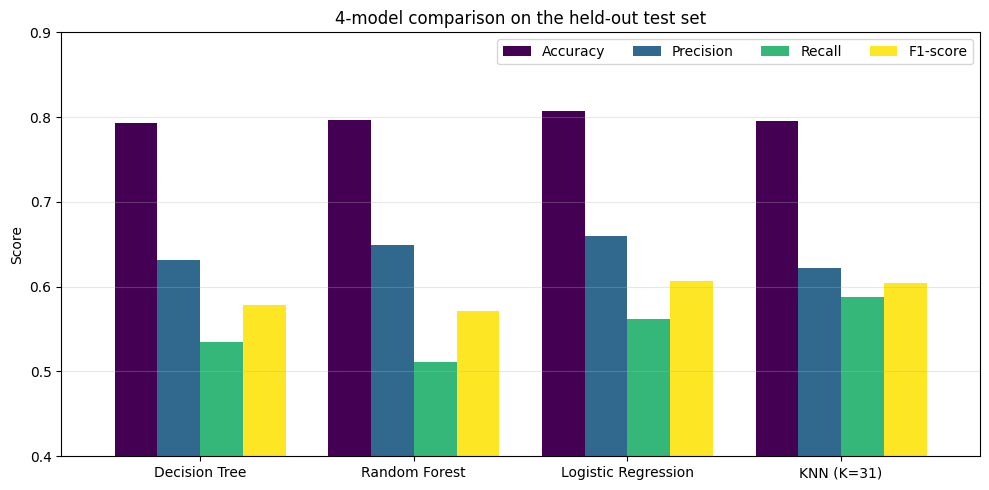

In [ ]:
ax = comparison.plot(kind="bar", figsize=(10, 5), width=0.8, colormap="viridis")
ax.set_ylim(0.4, 0.9); ax.set_ylabel("Score"); ax.set_title("4-model comparison on the held-out test set")
ax.grid(axis="y", alpha=.3); plt.xticks(rotation=0); plt.legend(loc="upper right", ncol=4)
plt.tight_layout(); plt.show()

**Interpretation.**
* **Best overall: Logistic Regression.** It has the best accuracy (≈ 80.7%), the best precision (≈ 66.0%) and the best F1 (≈ 0.607) of the four models. KNN is a very close second on F1 (≈ 0.604).
* **The ranking changes with the metric — but only for recall.** **KNN has the best recall (≈ 58.8%)**, i.e. it finds the most churners, but at the cost of the *lowest* precision (≈ 62.2%). The Random Forest and Decision Tree have the weakest recall (≈ 51% and ≈ 53%), so they miss the most churners. The Random Forest's precision (≈ 65.0%) is second only to Logistic Regression.
* **Which metric should carry the most weight?** Only ~26.5% of customers churn, so accuracy is inflated by the majority class (an "always No" model already gets ~73.5%). Missing a real churner (false negative) usually costs more than offering a retention discount to someone who wouldn't have left (false positive), so **recall and F1 on the churn class should carry the most weight, with precision as a guard against wasting retention budget.** By that standard Logistic Regression (best F1) and KNN (best recall) are the strongest candidates. The gap between them is tiny (≈ 0.003 F1), so it should not be over-interpreted from one split — see Part 7.

> *Note: all numbers in the written interpretations come from `random_state=42`. A different scikit-learn version in Colab can shift individual metrics by a few tenths of a percent; if a ranking between two very close models flips, adjust the wording to match your printed tables.*

---
# 6. Coefficient Interpretation
A logistic-regression coefficient is a change in the **log-odds** of churn per one-unit increase of the feature, other features held constant. `exp(coefficient)` converts it into an **odds ratio (OR)**: OR > 1 → higher odds of churn, OR < 1 → lower odds. Numeric features were standardised, so their OR is **per +1 standard deviation**; dummy features are **vs. the dropped baseline category**.

In [ ]:
sd = dict(zip(num_cols, scaler.scale_))   # original-unit standard deviations, for readable interpretation

def interpret(feature, coef):
    odds = np.exp(coef)
    direction = "higher" if odds > 1 else "lower"
    if feature in num_cols:
        return f"+1 SD in {feature} (≈ {sd[feature]:,.1f} units) → ≈ {odds:.2f}× the odds of churn ({direction})"
    if feature == "SeniorCitizen":
        return f"Senior citizens have ≈ {odds:.2f}× the odds of churn vs non-seniors ({direction})"
    base, _, level = feature.rpartition("_")
    return f"'{base} = {level}' has ≈ {odds:.2f}× the odds of churn vs the baseline category ({direction})"

coef_table = pd.DataFrame({"Feature": X_train_scaled.columns,
                           "Coefficient": logreg.coef_[0]})
coef_table["Odds Ratio"] = np.exp(coef_table["Coefficient"])
coef_table["Interpretation"] = [interpret(f, c) for f, c in zip(coef_table["Feature"], coef_table["Coefficient"])]
coef_table = coef_table.reindex(coef_table["Coefficient"].abs().sort_values(ascending=False).index).reset_index(drop=True)

print("Intercept:", round(float(logreg.intercept_[0]), 4))
pd.set_option("display.max_colwidth", 120)
coef_table.round(3)

Intercept: -1.5414


,Feature,Coefficient,Odds Ratio,Interpretation
0,Contract_Two year,-1.317,0.268,'Contract = Two year' has ≈ 0.27× the odds of churn vs the baseline category (lower)
1,tenure,-1.262,0.283,+1 SD in tenure (≈ 24.6 units) → ≈ 0.28× the odds of churn (lower)
2,InternetService_Fiber optic,1.129,3.092,'InternetService = Fiber optic' has ≈ 3.09× the odds of churn vs the baseline category (higher)
3,Contract_One year,-0.684,0.505,'Contract = One year' has ≈ 0.50× the odds of churn vs the baseline category (lower)
4,TotalCharges,0.534,1.706,"+1 SD in TotalCharges (≈ 2,279.0 units) → ≈ 1.71× the odds of churn (higher)"
5,PhoneService_Yes,-0.512,0.599,'PhoneService = Yes' has ≈ 0.60× the odds of churn vs the baseline category (lower)
6,MonthlyCharges,-0.413,0.662,+1 SD in MonthlyCharges (≈ 30.1 units) → ≈ 0.66× the odds of churn (lower)
7,PaymentMethod_Electronic check,0.386,1.471,'PaymentMethod = Electronic check' has ≈ 1.47× the odds of churn vs the baseline category (higher)
8,PaperlessBilling_Yes,0.372,1.451,'PaperlessBilling = Yes' has ≈ 1.45× the odds of churn vs the baseline category (higher)
9,OnlineSecurity_Yes,-0.360,0.698,'OnlineSecurity = Yes' has ≈ 0.70× the odds of churn vs the baseline category (lower)


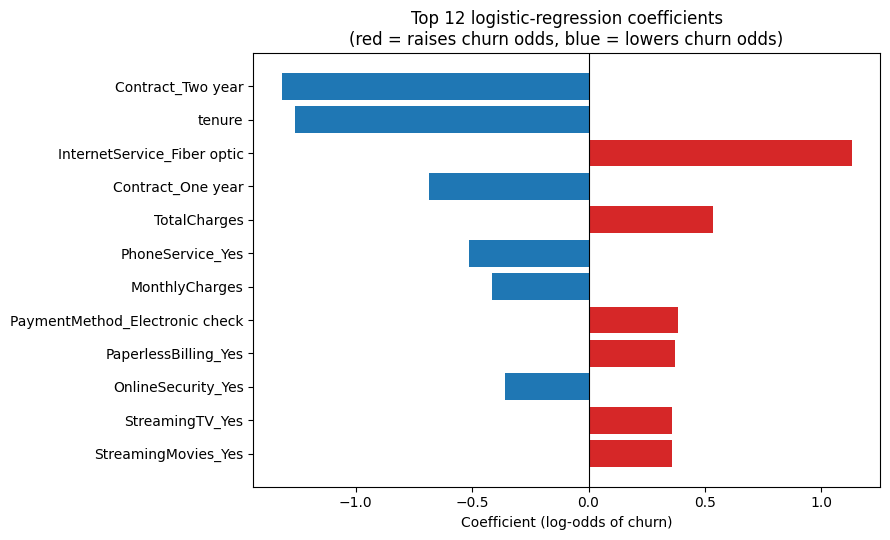

In [ ]:
top = coef_table.head(12).iloc[::-1]
plt.figure(figsize=(9, 5.5))
plt.barh(top["Feature"], top["Coefficient"], color=np.where(top["Coefficient"] > 0, "tab:red", "tab:blue"))
plt.axvline(0, color="black", lw=.8)
plt.xlabel("Coefficient (log-odds of churn)"); plt.title("Top 12 logistic-regression coefficients\n(red = raises churn odds, blue = lowers churn odds)")
plt.tight_layout(); plt.show()

### Interpretation of key features (holding all other features constant)
* **`InternetService_Fiber optic` — OR ≈ 3.09.** Fiber customers have roughly **3.1× the odds of churning** compared with DSL customers. This is the largest *risk-increasing* effect.
* **`Contract_Two year` — OR ≈ 0.27** and **`Contract_One year` — OR ≈ 0.51.** Compared with month-to-month customers, two-year contracts cut the odds of churn to about **27%** (roughly a 73% reduction) and one-year contracts to about **51%**.
* **`tenure` — OR ≈ 0.28 per +1 SD (≈ 24.6 months).** Every additional ~2 years of tenure multiplies churn odds by ≈ 0.28: loyal long-term customers rarely leave, new customers are the risk group.
* **`PaymentMethod_Electronic check` — OR ≈ 1.47** and **`PaperlessBilling_Yes` — OR ≈ 1.45.** Electronic-check and paperless-billing customers carry about 45–47% higher odds of churn than their baselines.
* **`StreamingTV_Yes` / `StreamingMovies_Yes` / `MultipleLines_Yes` — OR ≈ 1.42–1.43** (higher churn), while **`OnlineSecurity_Yes` (≈ 0.70) and `TechSupport_Yes` (≈ 0.73)** are protective: customers who have these support services churn less.
* **Cautions.** (1) `MonthlyCharges` (OR ≈ 0.66) and `TotalCharges` (OR ≈ 1.71) have counter-intuitive signs because they are strongly correlated with tenure and with the service dummies — once those are held fixed, the leftover "price" effect is not a clean causal effect. (2) All the "No internet service" dummies, and `InternetService_No`, are identical columns, so their coefficients are the same (−0.167 each) and only their **combined** effect (customers with no internet service) is meaningful — such customers churn far less. Coefficients show association, not causation.

In [ ]:
# Feature importances from the tree models (Labs 3-4) for comparison with the coefficients
imp = pd.DataFrame({"Decision Tree importance": dt.feature_importances_,
                    "Random Forest importance": rf.feature_importances_}, index=X.columns)
imp["LogReg |coef|"] = logreg.coef_[0].__abs__()
side = pd.concat({"Decision Tree – top 6": imp["Decision Tree importance"].nlargest(6).round(3).reset_index().rename(columns={"index": "feature"}),
                  "Random Forest – top 6": imp["Random Forest importance"].nlargest(6).round(3).reset_index().rename(columns={"index": "feature"}),
                  "Logistic Regression – top 6 |coef|": imp["LogReg |coef|"].nlargest(6).round(3).reset_index().rename(columns={"index": "feature"})}, axis=1)
side

Decision Tree – top 6                                    Random Forest – top 6                           \
                          feature Decision Tree importance                         feature Random Forest importance   
0                          tenure                    0.423                          tenure                    0.187   
1     InternetService_Fiber optic                    0.359                    TotalCharges                    0.161   
2  PaymentMethod_Electronic check                    0.037                  MonthlyCharges                    0.098   
3                    TotalCharges                    0.037     InternetService_Fiber optic                    0.066   
4                  MonthlyCharges                    0.024               Contract_Two year                    0.064   
5               MultipleLines_Yes                    0.024  PaymentMethod_Electronic check                    0.060   

  Logistic Regression – top 6 |coef|                
                             feature LogReg |coef|  
0                  Contract_Two year         1.317  
1                             tenure         1.262  
2        InternetService_Fiber optic         1.129  
3                  Contract_One year         0.684  
4                       TotalCharges         0.534  
5                   PhoneService_Yes         0.512

### Do these results agree with Lab 2's EDA and Lab 3's Decision Tree?
**Agreement.** The strongest signals match the earlier labs: **short tenure, month-to-month contracts, fiber-optic internet and electronic-check payment** are the patterns typically highlighted in Telco-churn EDA (*check this against your own Lab 2 plots*), and **`tenure` and `InternetService_Fiber optic` were the top two features in the Lab 3 Decision Tree** and also appear among the top Random Forest features. Logistic Regression confirms these relationships with a clear direction and size (fiber ≈ 3.1× odds, tenure strongly protective).

**Disagreements / differences.**
* **Contract type:** Logistic Regression ranks `Contract_Two year` as its *single largest* coefficient, whereas the Decision Tree gives it little importance — a depth-5 tree can get most of the same information from `tenure` (long-tenure customers are largely the contract customers), so the importance is split among correlated features; the Random Forest, which spreads importance across many correlated features, ranks it 5th.
* **Billing columns:** `MonthlyCharges` and `TotalCharges` are important in the Random Forest/Decision Tree (they are good for splitting) but have *opposite-direction, hard-to-interpret* coefficients in Logistic Regression because of multicollinearity (see cautions above).
* **Direction vs. magnitude:** Tree importances only say *how much* a feature is used, never whether it raises or lowers churn; the odds ratios add the direction and an effect size.

---
# 7. Final Model Selection & Conclusion
Lab 4 taught us **not to trust a single number from a single split**. Before choosing, we therefore also check each model with **5-fold stratified cross-validation on the training set** (scaling is done *inside* each fold via a pipeline, so there is no leakage).

In [ ]:
pre_scale = ColumnTransformer([("scale", StandardScaler(), num_cols)], remainder="passthrough")

models = {
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=200, max_depth=10, random_state=RANDOM_STATE),
    "Logistic Regression": Pipeline([("prep", pre_scale), ("clf", LogisticRegression(max_iter=1000))]),
    f"KNN (K={K_FINAL})":  Pipeline([("prep", pre_scale), ("clf", KNeighborsClassifier(n_neighbors=K_FINAL))]),
}
scoring = ["accuracy", "precision", "recall", "f1"]

cv_rows = {}
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=skf, scoring=scoring)
    cv_rows[name] = {m.capitalize() + " (mean)": res[f"test_{m}"].mean() for m in scoring}
    cv_rows[name]["F1 (± std)"] = res["test_f1"].std()
cv_table = pd.DataFrame(cv_rows).T
display(cv_table.round(4))

,Accuracy (mean),Precision (mean),Recall (mean),F1 (mean),F1 (± std)
Decision Tree,0.7907,0.6303,0.5137,0.5642,0.0369
Random Forest,0.8030,0.6738,0.5003,0.5740,0.0212
Logistic Regression,0.8025,0.6535,0.5445,0.5934,0.0305
KNN (K=31),0.7989,0.6331,0.5779,0.6041,0.0184


In [ ]:
final_table = pd.DataFrame({
    "Test Accuracy": comparison["Accuracy"], "Test Recall": comparison["Recall"], "Test F1": comparison["F1-score"],
    "CV Accuracy": cv_table["Accuracy (mean)"], "CV Recall": cv_table["Recall (mean)"], "CV F1": cv_table["F1 (mean)"],
    "CV F1 std": cv_table["F1 (± std)"],
})
final_table.round(4)

,Test Accuracy,Test Recall,Test F1,CV Accuracy,CV Recall,CV F1,CV F1 std
Decision Tree,0.7935,0.5348,0.5789,0.7907,0.5137,0.5642,0.0369
Random Forest,0.7970,0.5107,0.5719,0.8030,0.5003,0.5740,0.0212
Logistic Regression,0.8070,0.5615,0.6069,0.8025,0.5445,0.5934,0.0305
KNN (K=31),0.7956,0.5882,0.6044,0.7989,0.5779,0.6041,0.0184


**Interpretation of the evidence.** The two views agree on the big picture but not on every detail:
* **Single test split:** Logistic Regression is best on accuracy, precision and F1; KNN is best on recall.
* **5-fold CV (training data):** KNN has the best F1 (≈ 0.604) and recall; Logistic Regression is second on F1 (≈ 0.593) and is essentially tied with the Random Forest on accuracy (≈ 80.2–80.3%). The Decision Tree and Random Forest are clearly behind on recall and F1 in both views.
* **Noise level:** the fold-to-fold F1 standard deviation (≈ 0.02–0.04) is larger than the gap between Logistic Regression and KNN (≈ 0.003 on the test split, ≈ 0.011 in CV). This is exactly Lab 4's warning: **a difference of ~1 point on a single number is not reliable evidence that one model is better.** (KNN's CV figure is also slightly flattered because K was chosen with the same folds.)

### Final model: **Logistic Regression**
**Justification.** The evidence puts Logistic Regression and KNN clearly ahead of the Decision Tree and Random Forest on the metrics that matter for imbalanced churn (recall and F1), and statistically level with each other. Logistic Regression is chosen as the tie-break because it is the best model on the Part 5 test table for accuracy, precision and F1, its cross-validated results are close to KNN's, and it comes with **interpretable odds ratios (Part 6), probability outputs whose threshold can be tuned to the retention budget, no K to tune, and fast, lightweight prediction** (KNN has to keep and search the entire training set). If the business cared *only* about catching as many churners as possible at the default threshold, KNN would be the alternative — but the same recall gain can be obtained from Logistic Regression by lowering its threshold.

### Conclusion
Against the best of Labs 3–4 (the Random Forest: ≈ 79.7% accuracy, recall ≈ 51%, F1 ≈ 0.57), today's best model, **Logistic Regression**, improves accuracy to ≈ 80.7%, recall to ≈ 56% and F1 to ≈ 0.61 — a modest but consistent gain from a far simpler, more interpretable model. **Feature scaling** was essential for KNN: the same K = 31 model on raw features had recall ≈ 0.36 and F1 ≈ 0.47, versus ≈ 0.59 and ≈ 0.60 after scaling, because distance was dominated by the billing columns. It also made the Logistic Regression optimisation stable and its numeric coefficients comparable, while having no effect on the tree models. The remaining **limitations** are that recall is still only ≈ 56% (more than 4 in 10 churners are missed at the default 0.5 threshold), that the class imbalance was not addressed directly, that coefficients show association rather than causation and are distorted by correlated features (tenure, TotalCharges, the service dummies), and that the gaps between the top models are smaller than the cross-validation noise, so all conclusions rest on one dataset snapshot. **Next steps** would be to lower the decision threshold or use `class_weight="balanced"` to raise recall, tune hyper-parameters with cross-validation for every model, add engineered features (e.g. number of services, charge per month of tenure), and evaluate with ROC-AUC and precision–recall curves before deploying.